In [1]:

import pandas as pd

# Dataset kode untuk eksperimen Code Review
dataset = [
    {
        "id": "CODE_01",
        "code": """
def divide(a, b):
    return a / b
""",
        "expected_bug": "Tidak menangani pembagian dengan nol"
    },
    {
        "id": "CODE_02",
        "code": """
def calculate_average(numbers):
    total = sum(numbers)
    return total / len(numbers)
""",
        "expected_bug": "Tidak menangani list kosong"
    },
    {
        "id": "CODE_03",
        "code": """
def find_max(numbers):
    max_value = 0
    for number in numbers:
        if number > max_value:
            max_value = number
    return max_value
""",
        "expected_bug": "Inisialisasi nilai maksimum salah untuk semua angka negatif"
    },
    {
        "id": "CODE_04",
        "code": """
def add_item(item, items=[]):
    items.append(item)
    return items
""",
        "expected_bug": "Menggunakan mutable default argument"
    },
    {
        "id": "CODE_05",
        "code": """
def calculate_discount(price, discount):
    return price * discount / 100
""",
        "expected_bug": "Rumus menghitung harga setelah diskon salah"
    }
]

df = pd.DataFrame(dataset)

# Simpan dataset
df.to_csv("code_samples.csv", index=False)

print("DATASET BERHASIL DIBUAT")
print("Jumlah sampel:", len(df))
display(df[["id", "expected_bug"]])


DATASET BERHASIL DIBUAT
Jumlah sampel: 5


,id,expected_bug
0,CODE_01,Tidak menangani pembagian dengan nol
1,CODE_02,Tidak menangani list kosong
2,CODE_03,Inisialisasi nilai maksimum salah untuk semua ...
3,CODE_04,Menggunakan mutable default argument
4,CODE_05,Rumus menghitung harga setelah diskon salah


In [2]:
from google.colab import files

files.download("code_samples.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# Menampilkan kode tanpa kolom ground truth

for _, row in df.iterrows():
    print("=" * 50)
    print("ID:", row["id"])
    print(row["code"])


ID: CODE_01

def divide(a, b):
    return a / b

ID: CODE_02

def calculate_average(numbers):
    total = sum(numbers)
    return total / len(numbers)

ID: CODE_03

def find_max(numbers):
    max_value = 0
    for number in numbers:
        if number > max_value:
            max_value = number
    return max_value

ID: CODE_04

def add_item(item, items=[]):
    items.append(item)
    return items

ID: CODE_05

def calculate_discount(price, discount):
    return price * discount / 100



In [9]:
manual_results = [
    {"id": "CODE_01", "detected": 1, "time_seconds": 30},
    {"id": "CODE_02", "detected": 1, "time_seconds": 43},
    {"id": "CODE_03", "detected": 1, "time_seconds": 21},
    {"id": "CODE_04", "detected": 1, "time_seconds": 16},
    {"id": "CODE_05", "detected": 1, "time_seconds": 19}
]

manual_df = pd.DataFrame(manual_results)
display(manual_df)

,id,detected,time_seconds
0,CODE_01,1,30
1,CODE_02,1,43
2,CODE_03,1,21
3,CODE_04,1,16
4,CODE_05,1,19


In [10]:
manual_df = pd.DataFrame(manual_results)
manual_df.to_csv("manual_results.csv", index=False)

display(manual_df)

,id,detected,time_seconds
0,CODE_01,1,30
1,CODE_02,1,43
2,CODE_03,1,21
3,CODE_04,1,16
4,CODE_05,1,19


In [11]:

prompt = """
Act as a professional Python code reviewer.

Analyze the following Python code.

Tasks:
1. Identify all actual bugs.
2. Explain why each issue is a bug.
3. Suggest a correction for each bug.
4. If no bug exists, state that explicitly.

Do not invent bugs.
Focus on correctness and logical errors.

Return your answer in this format:
- Bug identified:
- Explanation:
- Suggested correction:

Code:
"""

for _, row in df.iterrows():
    print("=" * 60)
    print("SAMPLE:", row["id"])
    print(prompt)
    print(row["code"])


SAMPLE: CODE_01

Act as a professional Python code reviewer.

Analyze the following Python code.

Tasks:
1. Identify all actual bugs.
2. Explain why each issue is a bug.
3. Suggest a correction for each bug.
4. If no bug exists, state that explicitly.

Do not invent bugs.
Focus on correctness and logical errors.

Return your answer in this format:
- Bug identified:
- Explanation:
- Suggested correction:

Code:


def divide(a, b):
    return a / b

SAMPLE: CODE_02

Act as a professional Python code reviewer.

Analyze the following Python code.

Tasks:
1. Identify all actual bugs.
2. Explain why each issue is a bug.
3. Suggest a correction for each bug.
4. If no bug exists, state that explicitly.

Do not invent bugs.
Focus on correctness and logical errors.

Return your answer in this format:
- Bug identified:
- Explanation:
- Suggested correction:

Code:


def calculate_average(numbers):
    total = sum(numbers)
    return total / len(numbers)

SAMPLE: CODE_03

Act as a professional Pyt

In [14]:

llm_results = [
    {"id": "CODE_01", "detected": 0, "time_seconds": 12, "correct": 0},
    {"id": "CODE_02", "detected": 1, "time_seconds": 23, "correct": 1},
    {"id": "CODE_03", "detected": 1, "time_seconds": 39, "correct": 1},
    {"id": "CODE_04", "detected": 1, "time_seconds": 33, "correct": 1},
    {"id": "CODE_05", "detected": 0, "time_seconds": 17, "correct": 0}
]

llm_df = pd.DataFrame(llm_results)
display(llm_df)


,id,detected,time_seconds,correct
0,CODE_01,0,12,0
1,CODE_02,1,23,1
2,CODE_03,1,39,1
3,CODE_04,1,33,1
4,CODE_05,0,17,0


In [13]:
def calculate_average(numbers):
    total = sum(numbers)
    return total / len(numbers)

In [15]:

# KNOWLEDGE BASE untuk eksperimen RAG

knowledge_base = [
    {
        "topic": "Division by Zero",
        "content": """
        Pembagian dengan nol menyebabkan ZeroDivisionError.
        Program harus memeriksa apakah pembagi bernilai nol
        sebelum melakukan operasi pembagian.
        """
    },
    {
        "topic": "Empty List",
        "content": """
        Mengakses panjang list kosong untuk operasi pembagian
        dapat menyebabkan ZeroDivisionError.
        Periksa apakah list memiliki elemen sebelum menghitung rata-rata.
        """
    },
    {
        "topic": "Maximum Negative Number",
        "content": """
        Mencari nilai maksimum harus menggunakan elemen pertama
        sebagai nilai awal atau menggunakan fungsi max().
        Inisialisasi dengan nol dapat menghasilkan kesalahan
        apabila seluruh elemen bernilai negatif.
        """
    },
    {
        "topic": "Mutable Default Argument",
        "content": """
        Penggunaan list sebagai default argument pada fungsi Python
        dapat menyebabkan data terbagi antar pemanggilan fungsi.
        Gunakan None sebagai default dan buat list baru di dalam fungsi.
        """
    },
    {
        "topic": "Discount Calculation",
        "content": """
        Harga setelah diskon dihitung dengan rumus:
        harga akhir = harga awal - (harga awal * diskon / 100).
        Mengembalikan hanya nilai diskon bukan harga akhir.
        """
    }
]

print("Knowledge Base berhasil dibuat")
print("Jumlah dokumen:", len(knowledge_base))


Knowledge Base berhasil dibuat
Jumlah dokumen: 5


In [16]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Mengubah dokumen knowledge base menjadi vector
documents = [item["content"] for item in knowledge_base]

vectorizer = TfidfVectorizer()
document_vectors = vectorizer.fit_transform(documents)

print("Vectorization berhasil!")
print("Ukuran vector:", document_vectors.shape)


Vectorization berhasil!
Ukuran vector: (5, 67)


In [17]:

def retrieve_context(code, top_k=2):

    # Mengubah kode menjadi vector
    query_vector = vectorizer.transform([code])

    # Menghitung cosine similarity
    similarities = cosine_similarity(
        query_vector,
        document_vectors
    )[0]

    # Mengambil dokumen paling relevan
    top_indices = np.argsort(similarities)[::-1][:top_k]

    results = []

    for idx in top_indices:
        results.append({
            "topic": knowledge_base[idx]["topic"],
            "content": knowledge_base[idx]["content"],
            "similarity": round(float(similarities[idx]), 4)
        })

    return results


# Contoh pengujian
test_code = df.iloc[0]["code"]

retrieved = retrieve_context(test_code)

for item in retrieved:
    print("Topic:", item["topic"])
    print("Similarity:", item["similarity"])
    print("Context:", item["content"])
    print("-" * 40)


Topic: Discount Calculation
Similarity: 0.0
Context: 
        Harga setelah diskon dihitung dengan rumus:
        harga akhir = harga awal - (harga awal * diskon / 100).
        Mengembalikan hanya nilai diskon bukan harga akhir.
        
----------------------------------------
Topic: Mutable Default Argument
Similarity: 0.0
Context: 
        Penggunaan list sebagai default argument pada fungsi Python
        dapat menyebabkan data terbagi antar pemanggilan fungsi.
        Gunakan None sebagai default dan buat list baru di dalam fungsi.
        
----------------------------------------


In [18]:

def generate_rag_prompt(code, retrieved_docs):

    context = "\n".join([
        f"{item['topic']}: {item['content']}"
        for item in retrieved_docs
    ])

    prompt = f"""
You are a professional Python code reviewer.

Use the following retrieved knowledge as reference:

{context}

Review the following Python code.

Tasks:
1. Identify actual bugs.
2. Explain each bug.
3. Suggest corrections.
4. Do not invent bugs.
5. Use the retrieved knowledge when relevant.

Python Code:
{code}

Provide your findings in a structured format.
"""

    return prompt


# Generate RAG prompts for all samples
rag_prompts = []

for _, row in df.iterrows():

    retrieved_docs = retrieve_context(row["code"])

    generated_prompt = generate_rag_prompt(
        row["code"],
        retrieved_docs
    )

    rag_prompts.append({
        "id": row["id"],
        "retrieved_topics": [
            item["topic"] for item in retrieved_docs
        ],
        "prompt": generated_prompt
    })

print("RAG prompts berhasil dibuat!")
print("Jumlah sampel:", len(rag_prompts))


RAG prompts berhasil dibuat!
Jumlah sampel: 5


In [19]:
print(rag_prompts[0]["prompt"])


You are a professional Python code reviewer.

Use the following retrieved knowledge as reference:

Discount Calculation: 
        Harga setelah diskon dihitung dengan rumus:
        harga akhir = harga awal - (harga awal * diskon / 100).
        Mengembalikan hanya nilai diskon bukan harga akhir.
        
Mutable Default Argument: 
        Penggunaan list sebagai default argument pada fungsi Python
        dapat menyebabkan data terbagi antar pemanggilan fungsi.
        Gunakan None sebagai default dan buat list baru di dalam fungsi.
        

Review the following Python code.

Tasks:
1. Identify actual bugs.
2. Explain each bug.
3. Suggest corrections.
4. Do not invent bugs.
5. Use the retrieved knowledge when relevant.

Python Code:

def divide(a, b):
    return a / b


Provide your findings in a structured format.



In [21]:

for _, row in df.iterrows():
    print("\n", "=" * 50)
    print("ID:", row["id"])
    print("CODE:", row["code"])

    results = retrieve_context(row["code"])

    for result in results:
        print("Retrieved:", result["topic"])
        print("Similarity:", result["similarity"])



ID: CODE_01
CODE: 
def divide(a, b):
    return a / b

Retrieved: Discount Calculation
Similarity: 0.0
Retrieved: Mutable Default Argument
Similarity: 0.0

ID: CODE_02
CODE: 
def calculate_average(numbers):
    total = sum(numbers)
    return total / len(numbers)

Retrieved: Discount Calculation
Similarity: 0.0
Retrieved: Mutable Default Argument
Similarity: 0.0

ID: CODE_03
CODE: 
def find_max(numbers):
    max_value = 0
    for number in numbers:
        if number > max_value:
            max_value = number
    return max_value

Retrieved: Discount Calculation
Similarity: 0.0
Retrieved: Mutable Default Argument
Similarity: 0.0

ID: CODE_04
CODE: 
def add_item(item, items=[]):
    items.append(item)
    return items

Retrieved: Discount Calculation
Similarity: 0.0
Retrieved: Mutable Default Argument
Similarity: 0.0

ID: CODE_05
CODE: 
def calculate_discount(price, discount):
    return price * discount / 100

Retrieved: Discount Calculation
Similarity: 0.1433
Retrieved: Mutable Defau

In [22]:

knowledge_base = [
    {
        "topic": "Division by Zero",
        "content": """
        divide division divisor denominator zero
        pembagian dengan nol ZeroDivisionError.
        Check b == 0 before a / b.
        """
    },
    {
        "topic": "Empty List",
        "content": """
        calculate_average average numbers list empty
        len(numbers) zero division ZeroDivisionError.
        Check if list is empty before calculating average.
        """
    },
    {
        "topic": "Maximum Negative Number",
        "content": """
        find_max maximum max_value negative numbers
        initialize maximum with first element.
        Starting at zero fails for all negative values.
        """
    },
    {
        "topic": "Mutable Default Argument",
        "content": """
        add_item mutable default argument list items
        shared list between function calls.
        Use None instead of an empty list as default.
        """
    },
    {
        "topic": "Discount Calculation",
        "content": """
        calculate_discount price discount percentage
        final price after discount.
        price minus price times discount divided by 100.
        """
    }
]

documents = [item["content"] for item in knowledge_base]

vectorizer = TfidfVectorizer()
document_vectors = vectorizer.fit_transform(documents)

print("Knowledge base berhasil diperbarui!")


Knowledge base berhasil diperbarui!


In [23]:

rag_prompts = []

for _, row in df.iterrows():
    retrieved_docs = retrieve_context(row["code"])

    generated_prompt = generate_rag_prompt(
        row["code"],
        retrieved_docs
    )

    rag_prompts.append({
        "id": row["id"],
        "retrieved_topics": [
            item["topic"] for item in retrieved_docs
        ],
        "prompt": generated_prompt
    })

for item in rag_prompts:
    print("\nID:", item["id"])
    print("Retrieved:", item["retrieved_topics"])
    print(item["prompt"])
    print("=" * 60)



ID: CODE_01
Retrieved: ['Division by Zero', 'Discount Calculation']

You are a professional Python code reviewer.

Use the following retrieved knowledge as reference:

Division by Zero: 
        divide division divisor denominator zero
        pembagian dengan nol ZeroDivisionError.
        Check b == 0 before a / b.
        
Discount Calculation: 
        calculate_discount price discount percentage
        final price after discount.
        price minus price times discount divided by 100.
        

Review the following Python code.

Tasks:
1. Identify actual bugs.
2. Explain each bug.
3. Suggest corrections.
4. Do not invent bugs.
5. Use the retrieved knowledge when relevant.

Python Code:

def divide(a, b):
    return a / b


Provide your findings in a structured format.


ID: CODE_02
Retrieved: ['Empty List', 'Maximum Negative Number']

You are a professional Python code reviewer.

Use the following retrieved knowledge as reference:

Empty List: 
        calculate_average average

In [24]:
rag_results = [
    {"id": "CODE_01", "detected": 1, "time_seconds": 12, "correct": 1},
    {"id": "CODE_02", "detected": 1, "time_seconds": 26, "correct": 1},
    {"id": "CODE_03", "detected": 1, "time_seconds": 31, "correct": 1},
    {"id": "CODE_04", "detected": 1, "time_seconds": 28, "correct": 1},
    {"id": "CODE_05", "detected": 1, "time_seconds": 17, "correct": 1}
]

rag_df = pd.DataFrame(rag_results)
display(rag_df)

,id,detected,time_seconds,correct
0,CODE_01,1,12,1
1,CODE_02,1,26,1
2,CODE_03,1,31,1
3,CODE_04,1,28,1
4,CODE_05,1,17,1


In [25]:

# Menggabungkan hasil eksperimen

comparison = pd.DataFrame({
    "Method": ["Manual", "LLM", "LLM + RAG"],
    "Detected": [
        manual_df["detected"].sum(),
        llm_df["detected"].sum(),
        rag_df["detected"].sum()
    ],
    "Average Time (seconds)": [
        manual_df["time_seconds"].mean(),
        llm_df["time_seconds"].mean(),
        rag_df["time_seconds"].mean()
    ],
    "Correct Findings": [
        manual_df["detected"].sum(),
        llm_df["correct"].sum(),
        rag_df["correct"].sum()
    ]
})

display(comparison)


,Method,Detected,Average Time (seconds),Correct Findings
0,Manual,5,25.8,5
1,LLM,3,24.8,3
2,LLM + RAG,5,22.8,5


In [26]:
print("MANUAL RESULTS")
display(manual_df)

print("LLM RESULTS")
display(llm_df)

print("LLM + RAG RESULTS")
display(rag_df)

MANUAL RESULTS


,id,detected,time_seconds
0,CODE_01,1,30
1,CODE_02,1,43
2,CODE_03,1,21
3,CODE_04,1,16
4,CODE_05,1,19


LLM RESULTS


,id,detected,time_seconds,correct
0,CODE_01,0,12,0
1,CODE_02,1,23,1
2,CODE_03,1,39,1
3,CODE_04,1,33,1
4,CODE_05,0,17,0


LLM + RAG RESULTS


,id,detected,time_seconds,correct
0,CODE_01,1,12,1
1,CODE_02,1,26,1
2,CODE_03,1,31,1
3,CODE_04,1,28,1
4,CODE_05,1,17,1


In [27]:
comparison = pd.DataFrame({
    "Method": ["Manual", "LLM", "LLM + RAG"],
    "Detected": [
        manual_df["detected"].sum(),
        llm_df["correct"].sum(),
        rag_df["correct"].sum()
    ],
    "Detection Rate (%)": [
        manual_df["detected"].mean() * 100,
        llm_df["correct"].mean() * 100,
        rag_df["correct"].mean() * 100
    ],
    "Average Time (seconds)": [
        manual_df["time_seconds"].mean(),
        llm_df["time_seconds"].mean(),
        rag_df["time_seconds"].mean()
    ]
})

display(comparison)
comparison.to_csv("comparison_results.csv", index=False)

,Method,Detected,Detection Rate (%),Average Time (seconds)
0,Manual,5,100.0,25.8
1,LLM,3,60.0,24.8
2,LLM + RAG,5,100.0,22.8


In [28]:
detail_comparison = pd.DataFrame({
    "ID": df["id"],
    "Manual_Detected": manual_df["detected"],
    "LLM_Correct": llm_df["correct"],
    "RAG_Correct": rag_df["correct"],
    "Manual_Time": manual_df["time_seconds"],
    "LLM_Time": llm_df["time_seconds"],
    "RAG_Time": rag_df["time_seconds"]
})

display(detail_comparison)

detail_comparison.to_csv(
    "detail_comparison.csv",
    index=False
)

,ID,Manual_Detected,LLM_Correct,RAG_Correct,Manual_Time,LLM_Time,RAG_Time
0,CODE_01,1,0,1,30,12,12
1,CODE_02,1,1,1,43,23,26
2,CODE_03,1,1,1,21,39,31
3,CODE_04,1,1,1,16,33,28
4,CODE_05,1,0,1,19,17,17


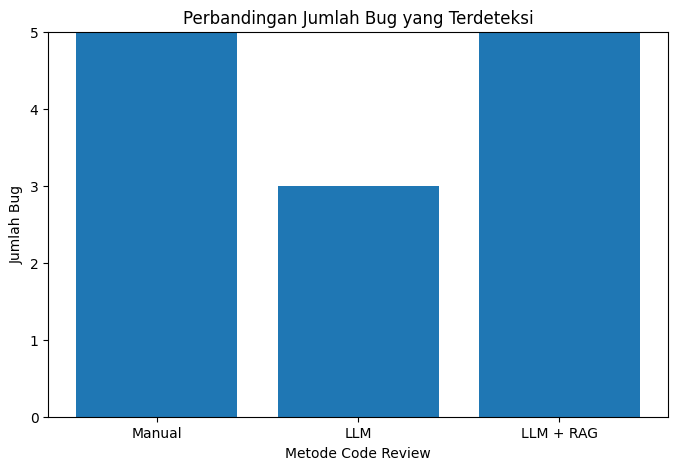

In [29]:
import matplotlib.pyplot as plt

methods = ["Manual", "LLM", "LLM + RAG"]
detection = [
    manual_df["detected"].sum(),
    llm_df["correct"].sum(),
    rag_df["correct"].sum()
]

plt.figure(figsize=(8, 5))
plt.bar(methods, detection)
plt.title("Perbandingan Jumlah Bug yang Terdeteksi")
plt.xlabel("Metode Code Review")
plt.ylabel("Jumlah Bug")
plt.ylim(0, 5)
plt.savefig("detection_comparison.png")
plt.show()

In [30]:
final_results = pd.DataFrame({
    "Method": ["Manual", "LLM", "LLM + RAG"],
    "Bugs_Detected": [
        manual_df["detected"].sum(),
        llm_df["correct"].sum(),
        rag_df["correct"].sum()
    ],
    "Detection_Rate": [
        manual_df["detected"].mean() * 100,
        llm_df["correct"].mean() * 100,
        rag_df["correct"].mean() * 100
    ],
    "Average_Time": [
        manual_df["time_seconds"].mean(),
        llm_df["time_seconds"].mean(),
        rag_df["time_seconds"].mean()
    ]
})

display(final_results)

final_results.to_csv("final_results.csv", index=False)

,Method,Bugs_Detected,Detection_Rate,Average_Time
0,Manual,5,100.0,25.8
1,LLM,3,60.0,24.8
2,LLM + RAG,5,100.0,22.8


In [31]:
# Hasil code review manual
manual_df.to_csv("manual_results.csv", index=False)

# Hasil code review menggunakan LLM
llm_df.to_csv("llm_results.csv", index=False)

# Hasil code review menggunakan LLM + RAG
rag_df.to_csv("rag_results.csv", index=False)

print("Semua hasil eksperimen berhasil disimpan!")

Semua hasil eksperimen berhasil disimpan!


In [38]:
from google.colab import files

files.download("manual_results.csv")
files.download("llm_results.csv")
files.download("rag_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# Hasil code review manual
manual_df.to_csv("comparison_results.csv", index=False)

# Hasil code review menggunakan LLM
llm_df.to_csv("detail_comparison.csv", index=False)

# Hasil code review menggunakan LLM + RAG
rag_df.to_csv("final_results.csv", index=False)

print("Semua hasil eksperimen berhasil disimpan!")

Semua hasil eksperimen berhasil disimpan!


In [39]:
from google.colab import files

files.download("comparison_results.csv")
files.download("detail_comparison.csv")
files.download("final_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>